# Exploratory Data Analysis (EDA), Parameterized Logistic Regression & Explainable AI (SHAP) for Phishing Detection

### École Nationale Supérieure d'intelligence Artificielle et Sciences des Données - Ibn Zohr University

**Master:** Intelligent Systems Security and Cyber Defense | **Module M115:** AI & Intelligent Systems

**Developed by:** Zakaria TAIRARI | **Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027

---
## Introduction

This practical work explores the application of supervised machine learning to cybersecurity, focusing on the detection of phishing URLs using Logistic Regression.

The study relies on the ```PhiUSIIL_Phishing_URL_Dataset``` (Prasad & Chandra, 2024), containing approximately 235,795 URLs described by 56 lexical, network, and HTML-based features.

The objective is to investigate the dataset, develop and compare different Logistic Regression configurations, evaluate their performance, and interpret their predictions using SHAP (SHapley Additive exPlanations). Particular attention is given to model reliability, feature importance, and decision thresholds in the context of SOC operations.

## 1. Security-Oriented Exploratory Data Analysis (EDA)

### 1.1 Data Quality Inspection & SOC Target Alignment

First, we import the packages we need and inspect the data, we check data quality, duplicates, and numerical feature scales.

In [58]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, confusion_matrix
import shap
warnings.filterwarnings('ignore')

df = pd.read_csv('datasets/PhiUSIIL_Phishing_URL_Dataset.csv')
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [60]:
df.isna().sum()

FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

In [61]:
df.duplicated().sum()

np.int64(0)

In [62]:
df.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


**Important Observation:**

In the raw ```PhiUSIIL``` file, ```label = 1``` designates a Legitimate site and ```label = 0``` designates a Phishing site. In a SOC, the positive class ( 1 ) must always represent the attack so that Precision and Recall measure threat detection.
To fix that we create the ```IsPhishing = 1 - df['label']``` ( 1 = Phishing , 0 = Legitimate ) and we check class proportions.

In [63]:
IsPhishing = 1 - df['label']
IsPhishing.value_counts(normalize=True)

label
0    0.571895
1    0.428105
Name: proportion, dtype: float64

### 1.2 Class Balance, Numerical Distributions & Binary Security Indicators

We visualize the class imbalance (```IsPhishing```) using a count plot.

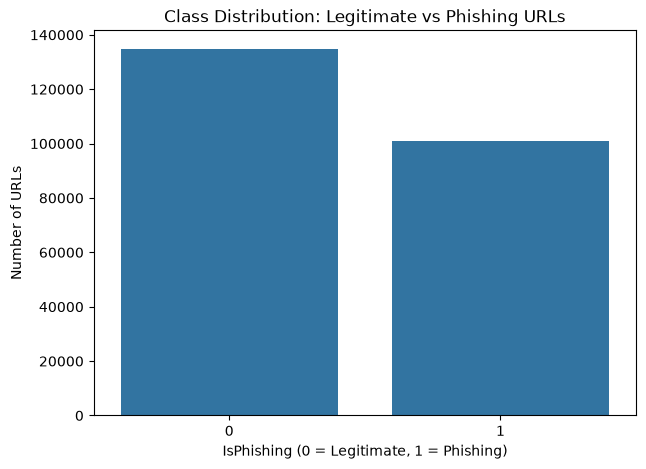

In [64]:
plt.figure(figsize=(7, 5))

sns.countplot(x=IsPhishing)

plt.title('Class Distribution: Legitimate vs Phishing URLs')
plt.xlabel('IsPhishing (0 = Legitimate, 1 = Phishing)')
plt.ylabel('Number of URLs')

plt.show()

We plot density curves to compare legitimate and phishing URLs across ```URLLength```, ```CharContinuationRate``` and ```NoOfSelfRef```. 

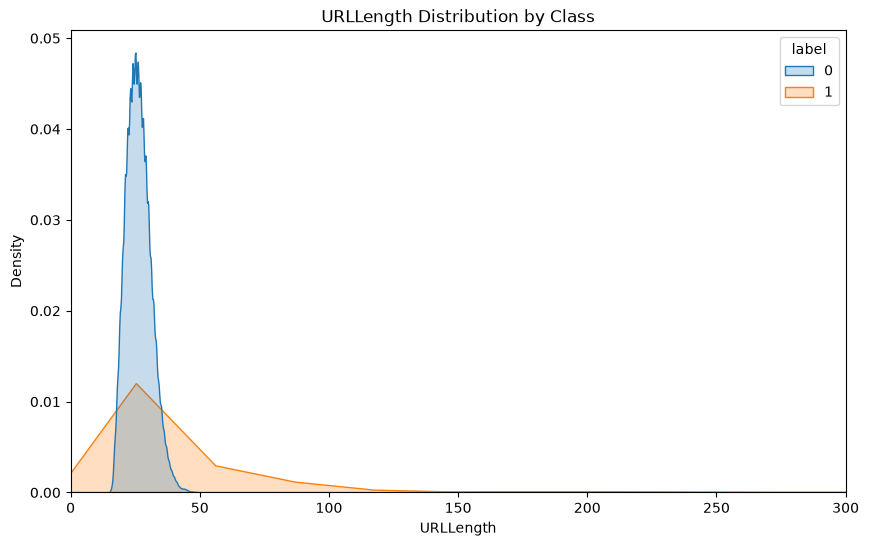

In [65]:
plt.figure(figsize=(10, 6))

sns.kdeplot(x=df['URLLength'], hue=IsPhishing, fill=True)

plt.xlim(0, 300)
plt.title('URLLength Distribution by Class')
plt.show()

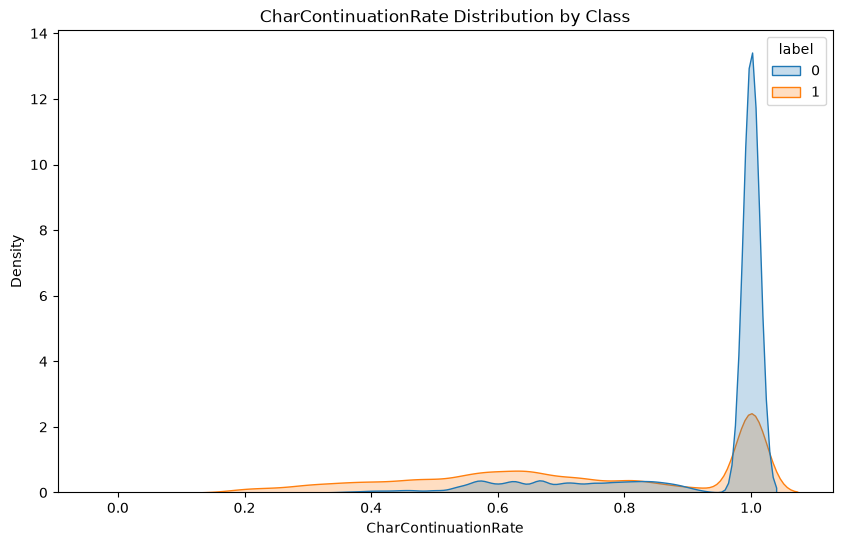

In [66]:
plt.figure(figsize=(10, 6))

sns.kdeplot(x=df['CharContinuationRate'], hue=IsPhishing, fill=True)

plt.title('CharContinuationRate Distribution by Class')
plt.show()

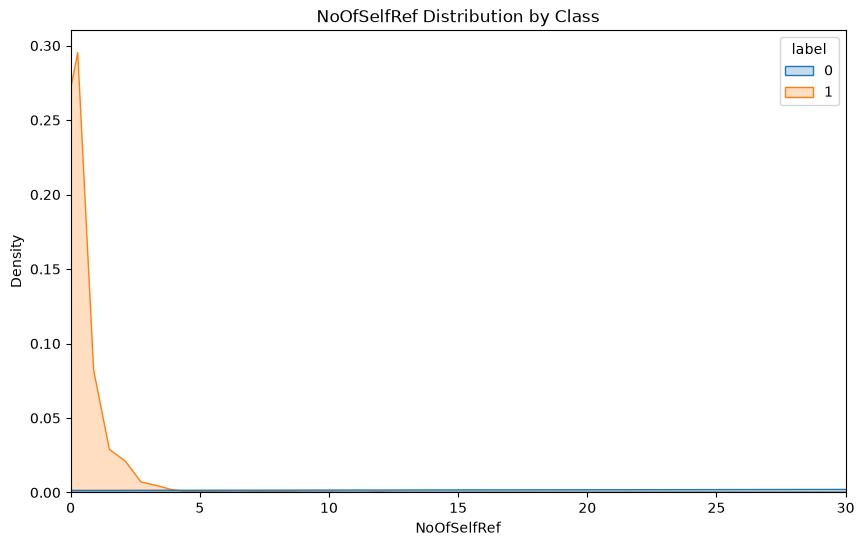

In [67]:
plt.figure(figsize=(10, 6))

sns.kdeplot(x=df['NoOfSelfRef'], hue=IsPhishing, fill=True)

plt.xlim(0, 30)
plt.title('NoOfSelfRef Distribution by Class')
plt.show()

We calculate and plot via bar charts the percentage prevalence of binary indicators per class: ```IsHTTPS``` ,```HasPasswordField``` , ```HasCopyrightInfo``` , and ```HasSocialNet```.

In [68]:
indicators = [
    'IsHTTPS',
    'HasPasswordField',
    'HasCopyrightInfo',
    'HasSocialNet'
]

#Calculate the prevelence
prevalence = pd.DataFrame({
    0: df.loc[IsPhishing == 0, indicators].mean() * 100,
    1: df.loc[IsPhishing == 1, indicators].mean() * 100
})

prevalence

,0,1
IsHTTPS,100.000000,49.223835
HasPasswordField,13.848721,5.387092
HasCopyrightInfo,80.823878,5.733815
HasSocialNet,79.455692,0.506216


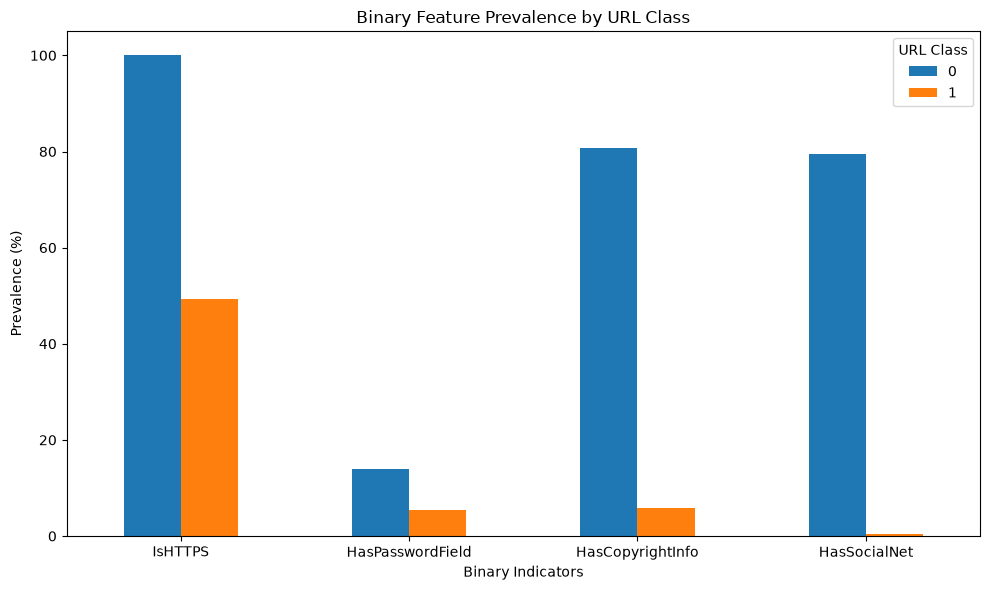

In [69]:
prevalence.plot(kind='bar', figsize=(10, 6))

plt.title('Binary Feature Prevalence by URL Class')
plt.xlabel('Binary Indicators')
plt.ylabel('Prevalence (%)')
plt.xticks(rotation=0)
plt.legend(title='URL Class')
plt.tight_layout()
plt.show()

### 1.3 Identifier Cleanup & Feature-Target Correlations

We start our cleanup by first dropping non-generalizable raw text columns (```FILENAME```, ```URL```, ```Domain```, ```TLD```, ```Title```), the original label column, and the pre-computed composite score ```URLSimilarityIndex``` so that the model learns from true lexical and HTML features.

In [70]:
df = df.drop(columns=['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label', 'URLSimilarityIndex'])
df.describe()

,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,0.024861,...,0.127089,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516
std,41.314153,9.150793,0.051946,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,1.876249,...,0.333074,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430
min,13.000000,4.000000,0.000000,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,27.000000,20.000000,0.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000
75%,34.000000,24.000000,0.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000
max,6097.000000,110.000000,1.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,447.000000,...,1.000000,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000


We build a clean feature matrix ```X``` and the target vector ```y = IsPhishing```, and we make sure that they have matching indexes.

In [71]:
X = df
y = IsPhishing
X.index.equals(y.index)

True

We calculate the Pearson correlation of each numerical feature in ```X``` with y and display the Top 15 positively and negatively correlated features in a horizontal bar plot.

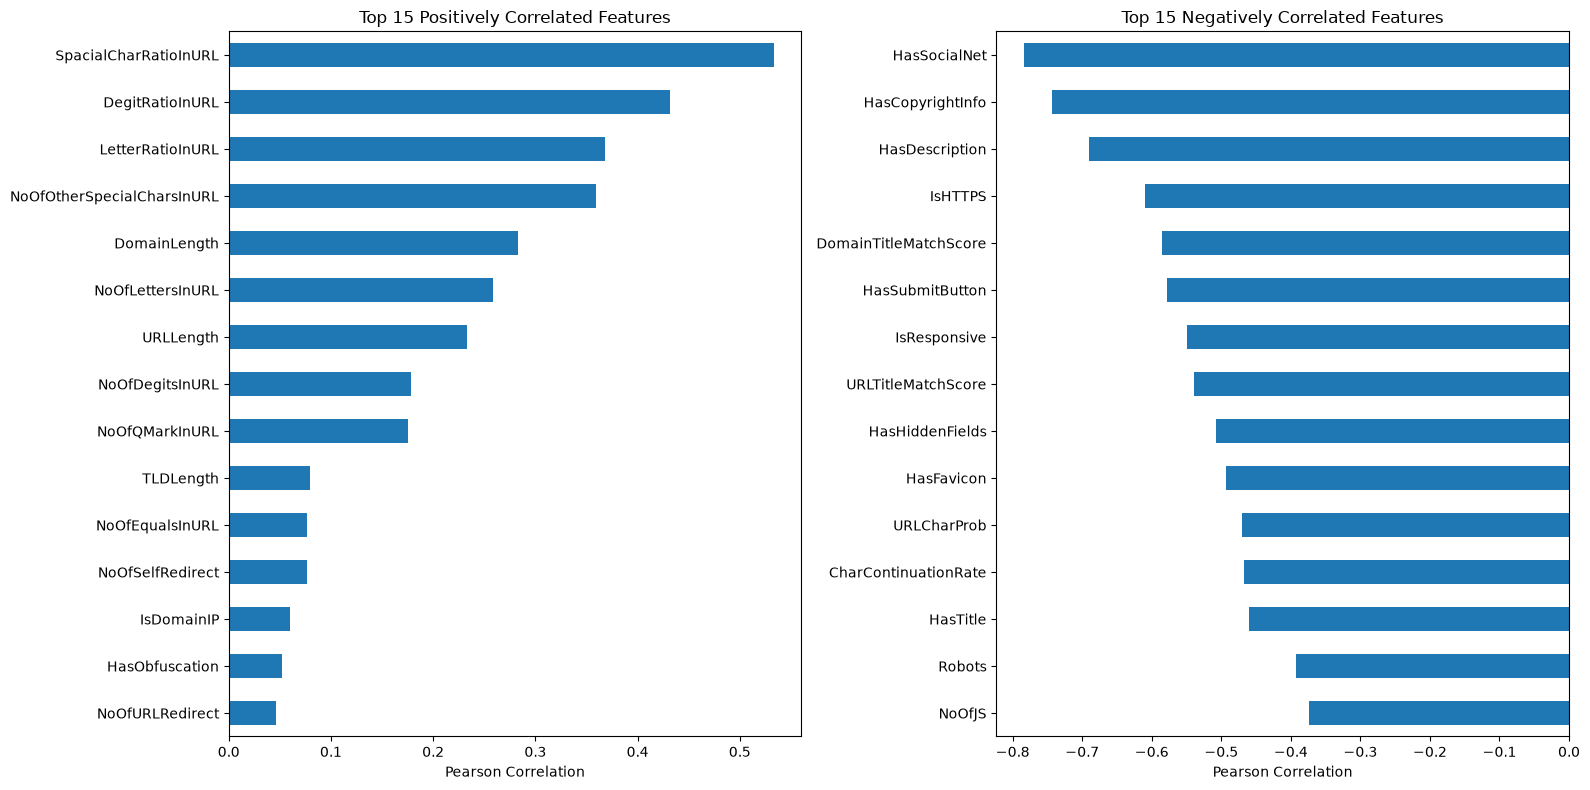

In [72]:
numerical_features = X.select_dtypes(include='number')

# Calculate Pearson correlation with the target
correlations = numerical_features.corrwith(y)

correlations = correlations.sort_values(ascending=False)

top_positive = correlations.head(15)
top_negative = correlations.tail(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Positive correlations
top_positive.sort_values().plot(
    kind='barh',
    ax=axes[0],
    title='Top 15 Positively Correlated Features'
)

# Negative correlations
top_negative.plot(
    kind='barh',
    ax=axes[1],
    title='Top 15 Negatively Correlated Features'
)

axes[0].set_xlabel('Pearson Correlation')
axes[1].set_xlabel('Pearson Correlation')

plt.tight_layout()
plt.show()

#### Reflection Questions Part 1:

1. Looking at your plot for ```IsHTTPS```, what percentage of phishing sites use an HTTPS certificate? Why is a static rule "If HTTPS then Legitimate" dangerous?

    Looking at our plot, it's true that 100% of legitimate sites use HTTPS, but also 49% of phishing sites use it, therefore a static rule If "HTTPS then Legitimate" is dangerous.


2. Why do phishing websites typically have very few internal links ( ```NoOfSelfRef``` ) but frequently contain a password field ( ```HasPasswordField``` )?

    Phishing sites typically have very few internal links because it's usually one page (often a login page) that tries to replicate the layout of a legitimate website page and attempts to deceive the victims into sending their personal informations (username, password) hence why they frequently contain a password field.


3. What would happen in production if we left raw string identifiers like ```FILENAME``` , ```URL``` , or ```Domain``` in our training matrix?

    if we leave raw string identifiers in production, the model might learn specific websites rather than general phishing characteristics (Overfitting).

---


## 2. Zero-Data Leakage Preprocessing & Standardization

### 2.1 Stratified 75/25 Split & Training-Only Standardization

We split X and y into a training set (75%) and a test set (25%).

In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (176846, 49) (176846,)
Test set: (58949, 49) (58949,)


We use ```StandardScaler``` and we fit and transform only the training set.

In [74]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled =  scaler.transform(X_test)

print("Training mean:\n", X_train_scaled.mean(axis=0))
print("Training std:\n", X_train_scaled.std(axis=0))

Training mean:
 [-6.18750672e-17 -1.59669816e-16  3.79286126e-17  2.87196740e-16
 -1.96714499e-16 -4.56429067e-17 -2.47500269e-17  1.25678708e-16
  1.29375140e-17  0.00000000e+00 -1.22946562e-17  3.80089698e-17
 -6.46714988e-16 -2.89286028e-18 -3.00536041e-17 -1.48259090e-17
 -2.81250305e-18  6.58929287e-18 -7.55357963e-18 -4.33446899e-16
 -6.91072179e-18 -2.20982383e-17  3.21428920e-18 -6.20357816e-17
 -1.18125128e-16  1.72285901e-16 -5.60893466e-17  5.86607780e-17
  4.43571910e-17  6.33214973e-17  5.04643405e-17 -4.87768387e-17
 -4.50000489e-18  2.42678835e-17 -1.54285882e-17 -9.24108146e-18
  6.66161438e-17  2.82857450e-17  3.88928994e-17  6.60536431e-17
 -2.54330633e-17 -3.90536138e-17 -5.94643503e-17  4.66071935e-18
  5.62500611e-18 -4.64263897e-17 -2.60357426e-17  9.64286761e-19
 -2.25000244e-18]
Training std:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1.]


#### Reflection Questions Part 2:

1. Compare the scale of ```LineOfCode``` (values up to 10,000+) and ```IsHTTPS``` (0 or 1) before standardization. Why would L1/L2 regularization be skewed without StandardScaler ?

    Without standardization, features with larger values can influence the model's descision more, causing L1/L2 regularization to penalize features unfairly.

2. Precisely explain why calling ```scaler.fit_transform(X)``` before ```train_test_split``` constitutes Preprocessing Data Leakage.

    Calling ```scaler.fit_transform(X)``` before ```train_test_split``` causes data leakage because the scaler calculates the mean and standard deviation using the entire dataset, including the future test set, this means information from the test data influences the preprocessing of the training data.
---


## 3. Training & Interpreting Parameterized Logistic Regression

We will experiment with five regularization regimes and mathematically interpret learned weights and Odds Ratios.

### 3.1 Experimental Comparison of the 5 Configurations

#### Model 1: Unregularized

In [75]:
M1 = LogisticRegression(C=np.inf, solver='lbfgs', max_iter=500, random_state=42)
M1.fit(X_train_scaled, y_train)

m1_y_pred = M1.predict(X_test_scaled)

# Prediction probabilities for the positive class (phishing = 1)
m1_y_proba = M1.predict_proba(X_test_scaled)[:, 1]

# Confusion matrix
m1_tn, m1_fp, m1_fn, m1_tp = confusion_matrix(y_test, m1_y_pred).ravel()

# Count coefficients close to zero
m1_zeroed_weights = np.sum(np.abs(M1.coef_[0]) < 1e-4)

m1_results = {
    'Precision': precision_score(y_test, m1_y_pred),
    'Recall (TPR)': recall_score(y_test, m1_y_pred),
    'F1-Score': f1_score(y_test, m1_y_pred),
    'PR-AUC': average_precision_score(y_test, m1_y_proba),
    'FP': m1_fp,
    'FN': m1_fn,
    'Zeroed Weights': m1_zeroed_weights
}

summary_df = pd.DataFrame([m1_results], index=['M1'])

summary_df

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
M1,0.999564,0.999009,0.999287,0.999994,11,25,0


#### Model 2: Strong L2 Ridge (C=0.001)

In [76]:
M2 = LogisticRegression(l1_ratio=0, C=0.001, solver='lbfgs', max_iter=500, random_state=42)
M2.fit(X_train_scaled, y_train)

m2_y_pred = M2.predict(X_test_scaled)

m2_y_proba = M2.predict_proba(X_test_scaled)[:, 1]

m2_tn, m2_fp, m2_fn, m2_tp = confusion_matrix(y_test, m2_y_pred).ravel()

m2_zeroed_weights = np.sum(np.abs(M2.coef_[0]) < 1e-4)

m2_results = {
    'Precision': precision_score(y_test, m2_y_pred),
    'Recall (TPR)': recall_score(y_test, m2_y_pred),
    'F1-Score': f1_score(y_test, m2_y_pred),
    'PR-AUC': average_precision_score(y_test, m2_y_proba),
    'FP': m2_fp,
    'FN': m2_fn,
    'Zeroed Weights': m2_zeroed_weights
}

summary_df.loc['M2'] = m2_results

summary_df

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
M1,0.999564,0.999009,0.999287,0.999994,11,25,0
M2,0.998451,0.995839,0.997143,0.999953,39,105,0


#### Model 3: Standard L2 Ridge (C=1.0)

In [77]:
M3 = LogisticRegression(l1_ratio=0, C=1.0, solver='lbfgs', max_iter=500, random_state=42)
M3.fit(X_train_scaled, y_train)

m3_y_pred = M3.predict(X_test_scaled)

m3_y_proba = M3.predict_proba(X_test_scaled)[:, 1]

m3_tn, m3_fp, m3_fn, m3_tp = confusion_matrix(y_test, m3_y_pred).ravel()

m3_zeroed_weights = np.sum(np.abs(M3.coef_[0]) < 1e-4)

m3_results = {
    'Precision': precision_score(y_test, m3_y_pred),
    'Recall (TPR)': recall_score(y_test, m3_y_pred),
    'F1-Score': f1_score(y_test, m3_y_pred),
    'PR-AUC': average_precision_score(y_test, m3_y_proba),
    'FP': m3_fp,
    'FN': m3_fn,
    'Zeroed Weights': m3_zeroed_weights
}

summary_df.loc['M3'] = m3_results

summary_df

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
M1,0.999564,0.999009,0.999287,0.999994,11,25,0
M2,0.998451,0.995839,0.997143,0.999953,39,105,0
M3,0.999603,0.998890,0.999247,0.999990,10,28,0


#### Model 4: Sparce L1 Lasso (C=0.01)

In [78]:
M4 = LogisticRegression(l1_ratio=1, C=0.01, solver='liblinear', max_iter=500, random_state=42)
M4.fit(X_train_scaled, y_train)

m4_y_pred = M4.predict(X_test_scaled)

m4_y_proba = M4.predict_proba(X_test_scaled)[:, 1]

m4_tn, m4_fp, m4_fn, m4_tp = confusion_matrix(y_test, m4_y_pred).ravel()

m4_zeroed_weights = np.sum(np.abs(M4.coef_[0]) < 1e-4)

m4_results_m4 = {
    'Precision': precision_score(y_test, m4_y_pred),
    'Recall (TPR)': recall_score(y_test, m4_y_pred),
    'F1-Score': f1_score(y_test, m4_y_pred),
    'PR-AUC': average_precision_score(y_test, m4_y_proba),
    'FP': m4_fp,
    'FN': m4_fn,
    'Zeroed Weights': m4_zeroed_weights
}

summary_df.loc['M4'] = m4_results_m4

summary_df

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
M1,0.999564,0.999009,0.999287,0.999994,11,25,0
M2,0.998451,0.995839,0.997143,0.999953,39,105,0
M3,0.999603,0.998890,0.999247,0.999990,10,28,0
M4,0.999285,0.997147,0.998215,0.999974,18,72,24


#### Model 5: SOC Weighted (balanced)

In [79]:
M5 = LogisticRegression(l1_ratio=0, C=1.0, class_weight='balanced', solver='lbfgs', max_iter=500, random_state=42)
M5.fit(X_train_scaled, y_train)

m5_y_pred = M5.predict(X_test_scaled)

m5_y_proba = M5.predict_proba(X_test_scaled)[:, 1]

m5_tn, m5_fp, m5_fn, m5_tp = confusion_matrix(y_test, m5_y_pred).ravel()

m5_zeroed_weights = np.sum(np.abs(M5.coef_[0]) < 1e-4)

m5_results = {
    'Precision': precision_score(y_test, m5_y_pred),
    'Recall (TPR)': recall_score(y_test, m5_y_pred),
    'F1-Score': f1_score(y_test, m5_y_pred),
    'PR-AUC': average_precision_score(y_test, m5_y_proba),
    'FP': m5_fp,
    'FN': m5_fn,
    'Zeroed Weights': m5_zeroed_weights
}

summary_df.loc['M5'] = m5_results

summary_df

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
M1,0.999564,0.999009,0.999287,0.999994,11,25,0
M2,0.998451,0.995839,0.997143,0.999953,39,105,0
M3,0.999603,0.998890,0.999247,0.999990,10,28,0
M4,0.999285,0.997147,0.998215,0.999974,18,72,24
M5,0.999485,0.999009,0.999247,0.999991,13,25,0


### 3.2 L1 Regularization Path (Feature Selection)

We vary C in [0.002, 0.01, 0.05, 0.1] with penalty='l1' and solver='liblinear', and plot the number of retained active features ($\vert{}w_j\vert{} \ge 10^{-4}$) on a log scale.

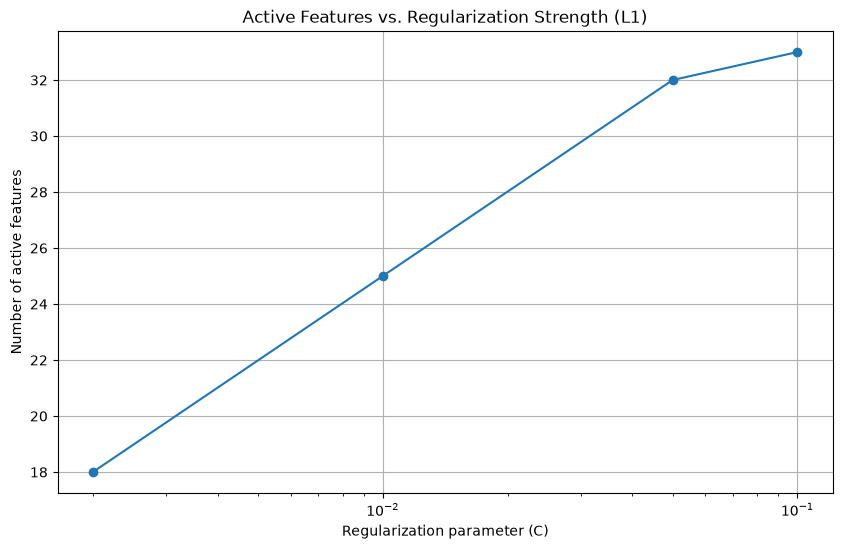

In [80]:
C_values = [0.002, 0.01, 0.05, 0.1]
active_features = []

for C in C_values:
    model = LogisticRegression(
        l1_ratio=1,
        solver='liblinear',
        C=C,
        max_iter=500,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    n_active = np.sum(np.abs(model.coef_) >= 1e-4)
    active_features.append(n_active)

plt.figure(figsize=(10, 6))
plt.plot(C_values, active_features, marker='o')
plt.xscale('log')
plt.xlabel('Regularization parameter (C)')
plt.ylabel('Number of active features')
plt.title('Active Features vs. Regularization Strength (L1)')
plt.grid(True)
plt.show()

### 3.3 Interpreting Log-Odds ($w_j$) and Odds Ratios ($e^{w_j}$)

We extract coefficients from M3 (standard L2 model), compute the Odds Ratio for each feature, and include the corresponding sparse weight from M4 (L1 sparse weight).

In [81]:
# Extract coefficients
l2_weights = M3.coef_[0]
l1_weights = M4.coef_[0]

# Build comparison DataFrame
feature_comparison = pd.DataFrame({
    'Feature': X.columns,
    'Weight (M3)': l2_weights,
    'Odds Ratio': np.exp(l2_weights),
    'L1_sparse_weight': l1_weights
})

# Separate positive and negative L2 weights
top_positive = (
    feature_comparison[feature_comparison['Weight (M3)'] > 0]
    .nlargest(8, 'Weight (M3)')
)

top_negative = (
    feature_comparison[feature_comparison['Weight (M3)'] < 0]
    .nsmallest(8, 'Weight (M3)')
)

print("Top 8 features increasing phishing risk:")
display(top_positive)

print("Top 8 features associated with legitimate sites:")
display(top_negative)

Top 8 features increasing phishing risk:


,Feature,Weight (M3),Odds Ratio,L1_sparse_weight
12,LetterRatioInURL,4.722849,112.488260,2.172552
14,DegitRatioInURL,3.605712,36.807888,1.803625
19,SpacialCharRatioInURL,3.598149,36.530556,1.910563
22,LargestLineLength,2.557525,12.903837,0.084806
18,NoOfOtherSpecialCharsInURL,2.083369,8.031482,0.000000
11,NoOfLettersInURL,1.680085,5.366011,0.000000
3,CharContinuationRate,1.420166,4.137806,0.000000
13,NoOfDegitsInURL,0.971770,2.642617,0.000000


Top 8 features associated with legitimate sites:


,Feature,Weight (M3),Odds Ratio,L1_sparse_weight
20,IsHTTPS,-6.902427,0.001005,-3.577657
45,NoOfJS,-3.653556,0.025899,-1.201656
46,NoOfSelfRef,-3.124918,0.043941,-0.822744
43,NoOfImage,-2.798141,0.060923,-0.150479
48,NoOfExternalRef,-2.641428,0.071259,-0.015705
21,LineOfCode,-2.367564,0.093709,0.000000
35,HasSocialNet,-2.153337,0.116096,-1.088651
1,DomainLength,-1.911745,0.147822,-0.058473


#### Reflection Questions Part 3:

1. How many variables did M4: Sparse L1 Lasso ( C=0.01 ) eliminate? Did the F1-Score or PR-AUC drop significantly? What is the advantage for a real-time firewall?

    M4 eliminated 24 features out of the original 49, F1-Score and RP-AUC didn't drop significantly, this would be very advantagious for a real-time firewall, fewer active features mean less computation required during prediction, lower memory usage and faster inference.

2. What is the impact of ```class_weight='balanced'``` (M5) on False Positives and False Negatives compared to M3?

    Setting class weight to balanced slightly drops the false negatives while increasing the false positives.

3. How do you interpret a positive weight $w_j > 0$ ($e^{w_j} > 1$) versus a negative weight $w_j < 0$ ($e^{w_j} < 1$) in $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?

    A positive weight means that increasing the feature's value increases the probability of phishing, a negative weight is the opposite, so increasing the value would decrease that probability.
---


## 4. Model Explainability (SHAP) & SOC Threshold Analysis

### 4.1 Global SHAP Explanations

We will use SHAP to know which exact features triggered the alert and how decision thresholds govern alert volume.

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


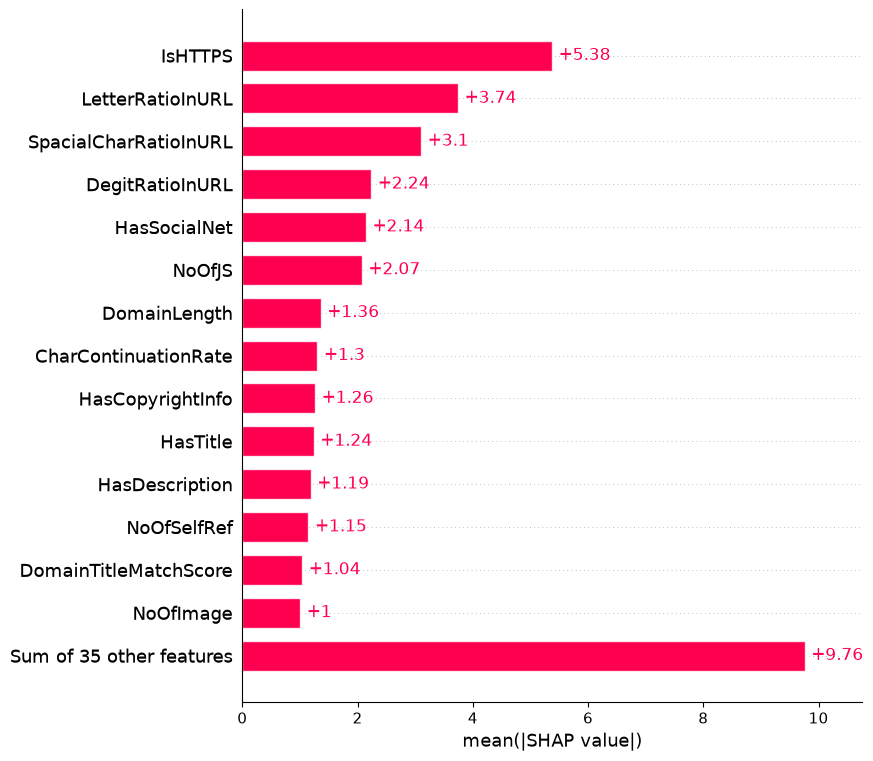

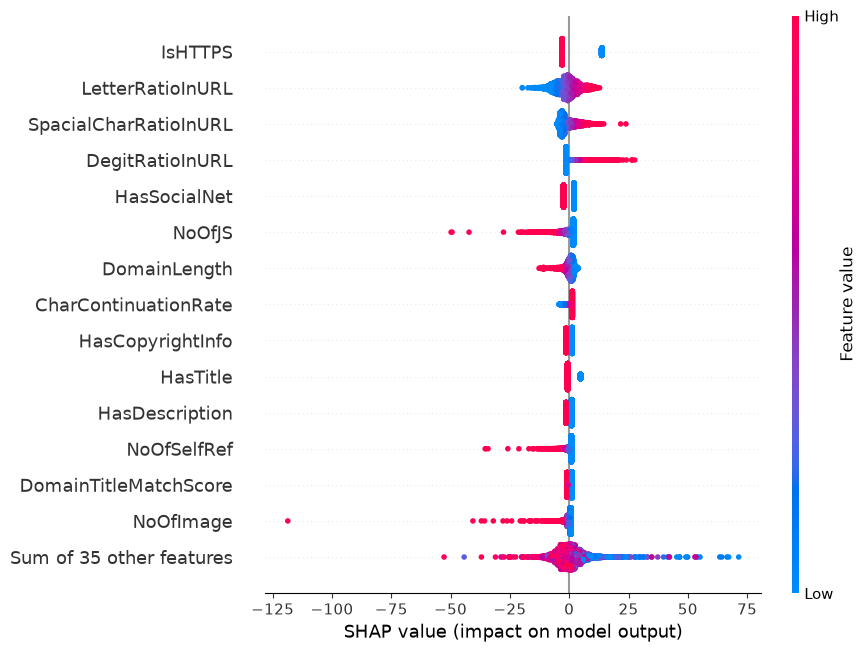

In [82]:
X_train_df = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=y_train.index
)

X_test_df = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=y_test.index
)

explainer = shap.LinearExplainer(M3, X_train_df)

shap_values = explainer(X_test_df.iloc[:4000])

shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)

### 4.2 Local SOC Alert Triage (TP, TN, and FP Waterfall Plots)

Within our 4000-URL test sample, we identify the index of a True Positive (TP), a True Negative (TN), and a False Positive, for each of the 3 cases, we use the Waterfall plot to inspect how $\phi_0 + \sum \phi_j(x)$ transitions from $E[f(X)]$ to $f(x)$.

TP index: 2
TN index: 0
FP index: 3590


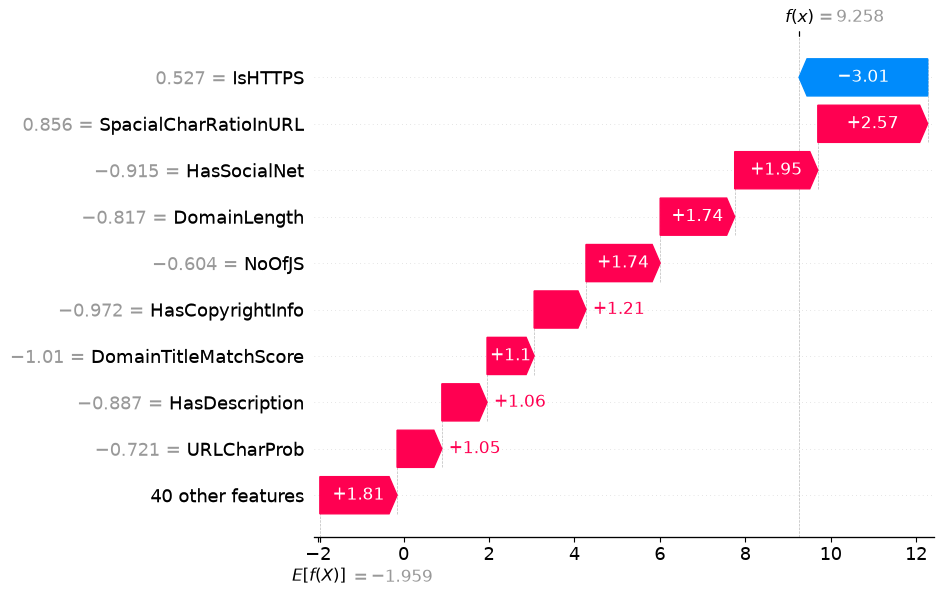

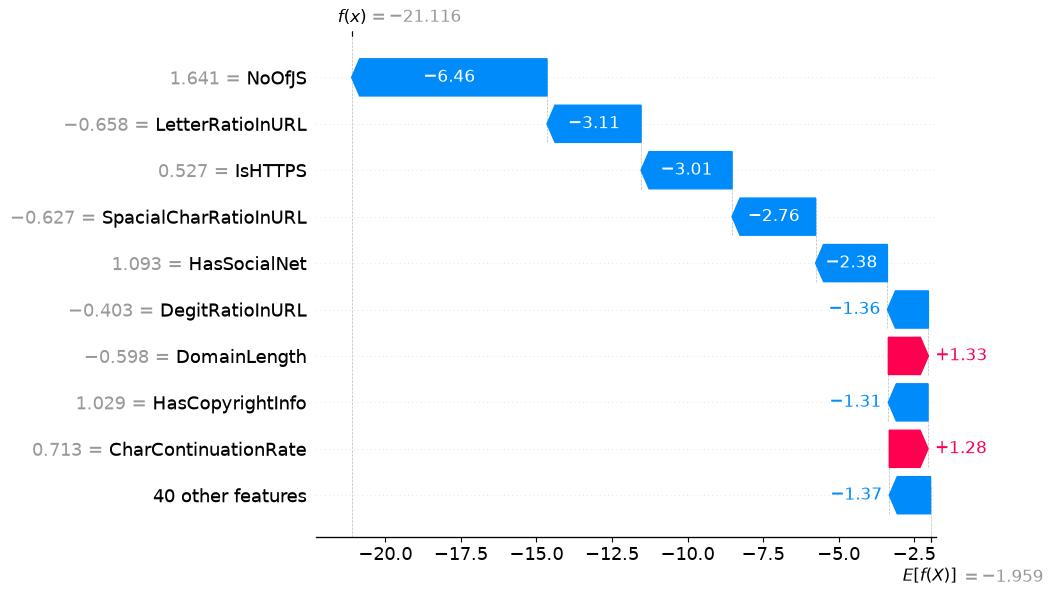

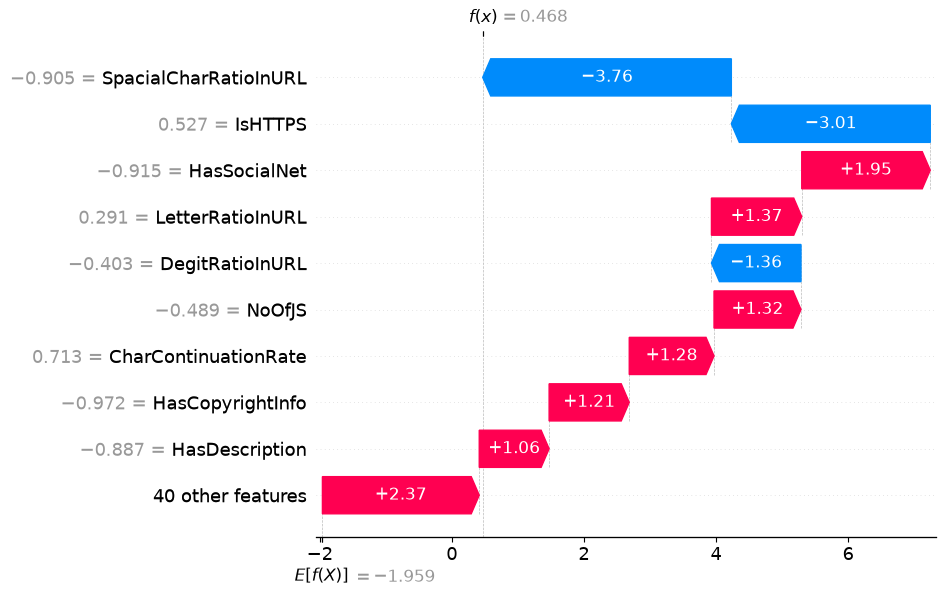

In [83]:
# Find the position of the first occurrence of each case
tp_idx = np.where((y_test == 1) & (m3_y_pred == 1))[0][0]
tn_idx = np.where((y_test == 0) & (m3_y_pred == 0))[0][0]
fp_idx = np.where((y_test == 0) & (m3_y_pred == 1))[0][0]

print("TP index:", tp_idx)
print("TN index:", tn_idx)
print("FP index:", fp_idx)

shap.plots.waterfall(shap_values[tp_idx], max_display=10)
shap.plots.waterfall(shap_values[tn_idx], max_display=10)
shap.plots.waterfall(shap_values[fp_idx], max_display=10)

### 4.3 Operational Decision Threshold Tuning ($\tau$)

Using predicted probabilities from M3 on the full test set, compare confusion matrices (TP, TN, FP, FN), Precision, Recall, and F1-Score across three operational thresholds: $\tau = 0.20$ (Threat Hunting mode),
$\tau = 0.50$ (Default mode), and $\tau = 0.85$ (Automated Firewall Blocking mode).

In [84]:
thresholds = [0.20, 0.50, 0.85]

threshold_results = []

for threshold in thresholds:

    # Convert probabilities into binary predictions
    m3_y_pred = (m3_y_proba >= threshold).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_test, m3_y_pred).ravel()

    # Calculate metrics
    results = {
        'Threshold': threshold,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'Precision': precision_score(y_test, m3_y_pred),
        'Recall': recall_score(y_test, m3_y_pred),
        'F1-Score': f1_score(y_test, m3_y_pred)
    }

    threshold_results.append(results)

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,Threshold,TP,TN,FP,FN,Precision,Recall,F1-Score
0,0.20,25221,33682,31,15,0.998772,0.999406,0.999089
1,0.50,25208,33703,10,28,0.999603,0.998890,0.999247
2,0.85,25172,33713,0,64,1.000000,0.997464,0.998730


#### Reflection Questions Part 4:

1. What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value $\phi_j(x)$ for a specific URL?

   Global weight represents the general influence of a feature on the model's log-odds of phishing, it's fixed across all URLs. Local SHAP value represents how much a feature contributes to the prediction of one specific URL.

2. On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?

    The 2 features that mislead the model the most were: ```HasSocialNet``` and ```LetterRatioInURL```.

3. Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le P(\text{Phishing}) < 0.85$ to a human analyst queue?

    A threshold of 0.85 produces very minimal FPs if any, therefore it would be suitable for automated DNS/firewall blocking, on the other hand, thresholds between 0.20 and 0.85 can produce some FPs and require manual analysis.
---

## SOC Engineering Synthesis

#### 1. Model Selection

M3 standard L2 (C=1.0) offers the best overall predictive performance, achieving 99% in precision, recall, and PR-AUC, with only 10 false positives and 28 false negatives. Although M4 sparse L1 (C=0.01) eliminates 24 of the 49 features, this comes at the cost of 44 additional false negatives. Therefore, M3 is preferred for detection reliability, while M4 represents a more compact alternative when model sparsity is prioritized.

#### 2. Global Feature Interpretation – Odds Ratios & SHAP

The strongest global phishing indicators were ```LetterRatioInURL``` and ```DigitRatioInURL```, while the strongest benign indicators were ```isHTTPS``` and ```NoOfJS```, these findings are supported by the model's Odds Ratios and global SHAP feature importance.

#### 3. SOC Triage Policy – False Positive Analysis

The False Positive waterfall shows that ```HasSocialNet``` and ```LetterRatioInURL``` contributed most strongly toward the incorrect phishing prediction. This suggests that the model associated certain legitimate URL characteristics with phishing behavior. I recommend automated blocking at τ ≥ 0.85 and analyst review for 0.20 ≤ τ < 0.85.
